# Neural network: predict position (multi-position aware)
**Task:** classify outfield players as DF / MF / FW from playing-style stats, with position hidden.

**Fix:** a player listed as `MF,FW` is **correct if the prediction is either MF or FW**. Training also respects this: each dual-position player contributes one row per listed position (duplicated rows, since `MLPClassifier` has no sample weights).

**Leakage guard:** train/test split is per player *before* rows are duplicated. No `Pos` / `Pos_stats_*` column is a feature. Early stopping is off, because its internal validation split would otherwise put duplicate rows of one player on both sides.

**Model:** scikit-learn `MLPClassifier`, scaler inside the pipeline.

In [1]:
%pip install -q scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
df = pd.read_csv('players_data-2026_2027.csv'); print(df.shape)

(2295, 102)


In [2]:
d = df[df['Pos'].notna() & ~df['Pos'].str.contains('GK')].copy()
d = d[d['90s'] >= 3].drop_duplicates(subset=['Player','Squad']).reset_index(drop=True)
names = ['DF','MF','FW']
d['pos_set'] = d['Pos'].str.split(',').apply(lambda l: [p.strip() for p in l if p.strip() in names])
d = d[d['pos_set'].str.len() > 0].reset_index(drop=True)
d['multi'] = d['pos_set'].str.len() > 1

counts = ['Gls','Ast','Sh','SoT','Crs','Int','TklW','Fld','Fls','Off','CrdY','CrdR','PKatt']
for k in counts: d[k+'_90'] = d[k] / d['90s']
feats = [k+'_90' for k in counts] + ['Age','Min%','Mn/Start','Starts','90s']
feats = [f for f in feats if f in d.columns]
d[feats] = d[feats].fillna(0)
assert not any('Pos' in f for f in feats)
print(len(d), 'players |', d['multi'].sum(), 'list more than one position')

1268 players | 227 list more than one position


Test accuracy (any listed position counts): 0.783
Old metric (first-listed position only):     0.701
Single-position players: 0.744 | Multi-position players: 0.977


/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


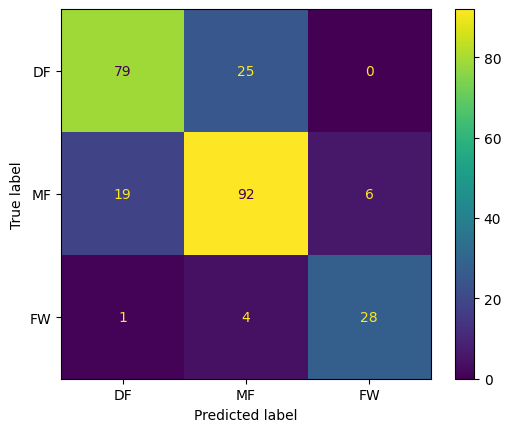

In [3]:
idx = {n:i for i,n in enumerate(names)}
def expand(frame):
    rows = frame.explode('pos_set')
    return rows[feats], rows['pos_set'].map(idx)

def set_accuracy(model, frame):
    pred = model.predict(frame[feats])
    ok = np.array([names[p] in s for p, s in zip(pred, frame['pos_set'])])
    return ok.mean(), pred, ok

def make():
    return make_pipeline(StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(32,16), alpha=1e-2, max_iter=500, random_state=42))

tr, te = train_test_split(d, test_size=0.2, random_state=42)
Xtr, ytr = expand(tr)
nn = make().fit(Xtr, ytr)
acc, pred, ok = set_accuracy(nn, te)
first = te['pos_set'].str[0].map(idx).values
print('Test accuracy (any listed position counts): %.3f' % acc)
print('Old metric (first-listed position only):     %.3f' % (pred == first).mean())
print('Single-position players: %.3f | Multi-position players: %.3f' % (ok[~te['multi'].values].mean(), ok[te['multi'].values].mean()))
true_for_cm = [names[p] if names[p] in s else s[0] for p, s in zip(pred, te['pos_set'])]
ConfusionMatrixDisplay(confusion_matrix(true_for_cm, [names[p] for p in pred], labels=names), display_labels=names).plot(); plt.show()

/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


5-fold accuracy (any listed position counts): 0.767 +/- 0.013


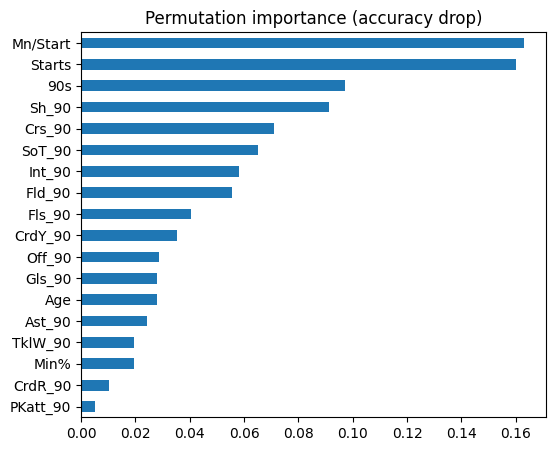

In [4]:
accs = []
for a, b in KFold(5, shuffle=True, random_state=42).split(d):
    X_, y_ = expand(d.iloc[a]); accs.append(set_accuracy(make().fit(X_, y_), d.iloc[b])[0])
print('5-fold accuracy (any listed position counts): %.3f +/- %.3f' % (np.mean(accs), np.std(accs)))

from sklearn.inspection import permutation_importance
tei = te.copy(); tei['y'] = [names.index(names[p]) if names[p] in s else idx[s[0]] for p, s in zip(pred, te['pos_set'])]
r = permutation_importance(nn, te[feats], tei['y'], n_repeats=20, random_state=42)
pd.Series(r.importances_mean, feats).sort_values().plot.barh(figsize=(6,5), title='Permutation importance (accuracy drop)'); plt.show()

In [5]:
proba = pd.DataFrame(nn.predict_proba(te[feats]), columns=names, index=te.index).round(2)
res = pd.concat([te[['Player','Squad','Pos']], proba], axis=1)
res['pred'] = [names[p] for p in pred]; res['correct'] = ok
print('Wrong even with multi-position credit, most confident first')
res[~res.correct].assign(conf=proba.max(axis=1)).sort_values('conf', ascending=False).head(15)

Wrong even with multi-position credit, most confident first


,Player,Squad,Pos,DF,MF,FW,pred,correct,conf
974,Federico Redondo,Elche,DF,0.00,1.00,0.00,MF,False,1.00
575,Christian Kabasele,Udinese,DF,0.00,1.00,0.00,MF,False,1.00
58,Jon Aramburu,Real Sociedad,DF,0.00,1.00,0.00,MF,False,1.00
543,Merwan Ifnaoui,Troyes,"FW,MF",1.00,0.00,0.00,DF,False,1.00
746,Ephron Mason-Clark,Coventry City,MF,0.00,0.01,0.99,FW,False,0.99
196,Lamine Camara,Monaco,MF,0.99,0.01,0.00,DF,False,0.99
532,Morten Hjulmand,Atlético Madrid,MF,0.99,0.01,0.00,DF,False,0.99
140,Antonio Blanco,Alavés,MF,0.98,0.02,0.00,DF,False,0.98
1107,Djibril Sow,Genoa,MF,0.98,0.02,0.00,DF,False,0.98
888,Fredrik Oppegard,Auxerre,MF,0.97,0.03,0.00,DF,False,0.97


**Notes:** dual-position players are easy to score because two of three answers are accepted, so compare the single-position figure too. Try tuning `hidden_layer_sizes` / `alpha`, or add passing and defending stats.